# 5 · Temporal single-system (TSSI) valuation

The simultaneist (Sraffian) view values the inputs used at time `t` at the prices of time `t`. The temporal single-system interpretation (Kliman & McGlone; Freeman & Carchedi) values them at the prices at which they were actually bought, here `t − τ` for a fixed production lag `τ`. Under TSSI, total price equals total value and total profit equals total surplus value by construction.

In MarxKapital, TSSI is a **valuation layer** over a simulated trajectory: it does not change the dynamics. The recursion `p(t) = mapa_tssi(p(t − τ), dados(t))` is a delay difference equation in continuous time, discretized with step `h`.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital carregado. Escreva  ajuda_modelo()  para começar.


Plots.GRBackend()

## 1. A trajectory to value

Six coupled departments with aggregate realization pressure. TSSI needs gross output, reconstructed as `xⱼ = Wⱼ/(1 − Σᵢ A[i,j])`, so every column of `A` must sum to less than one; the coupled run with realization guarantees that.

In [2]:
Random.seed!(5)
sol, depts, p = simular_Ndept(6, T = 60.0, seed = 5, acoplado = true, realização = true)
v = valorizar_tssi(sol, p; τ = 1.0, h = 0.5)
(erro_invariantes = v.erro_invariantes, r_tssi = extrema(v.r_tssi),
 r_simultâneo = extrema(v.r_simultâneo))

(erro_invariantes = 7.777685349450115e-16, r_tssi = (0.84004694644222, 0.8689286171283522), r_simultâneo = (0.8401259530666649, 0.8688323787053485))

`erro_invariantes` is the largest relative error of the two invariances along the trajectory: zero up to rounding.

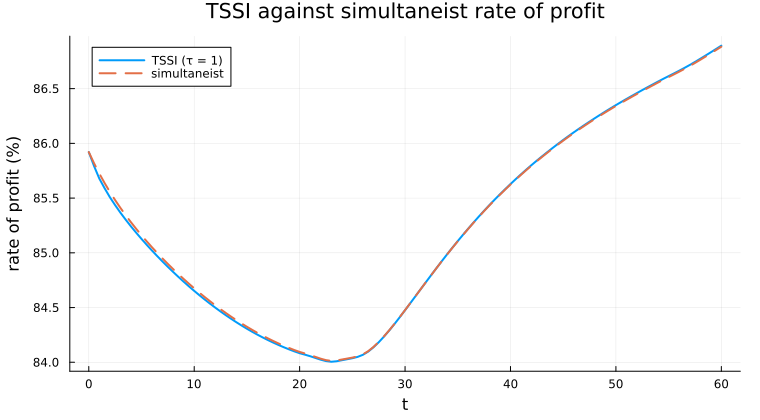

In [3]:
plot(v.t, 100 .* v.r_tssi, lw = 2, label = "TSSI (τ = 1)", xlabel = "t",
     ylabel = "rate of profit (%)", title = "TSSI against simultaneist rate of profit")
plot!(v.t, 100 .* v.r_simultâneo, lw = 2, ls = :dash, label = "simultaneist")

## 2. The production lag

A longer lag values the capital advanced at older prices. `τ` must be a multiple of the grid step `h`.

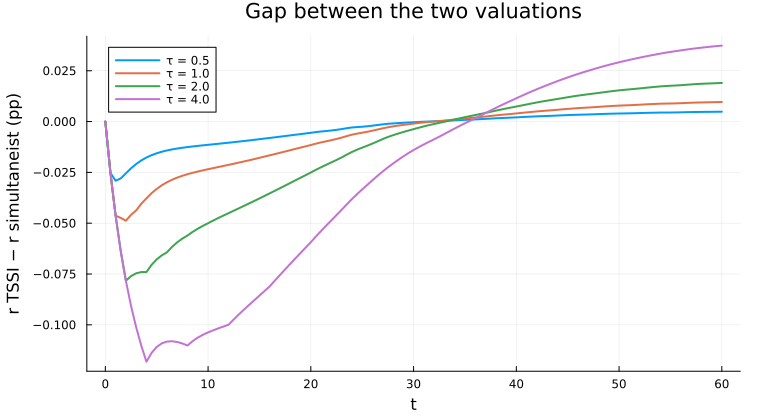

In [4]:
plt = plot(xlabel = "t", ylabel = "r TSSI − r simultaneist (pp)",
           title = "Gap between the two valuations")
for τ in (0.5, 1.0, 2.0, 4.0)
    vτ = valorizar_tssi(sol, p; τ = τ, h = 0.5)
    plot!(plt, vτ.t, 100 .* (vτ.r_tssi .- vτ.r_simultâneo), lw = 2, label = "τ = $τ")
end
plt

Sectoral TSSI prices, relative to the base-period price of 1 per unit of gross output:

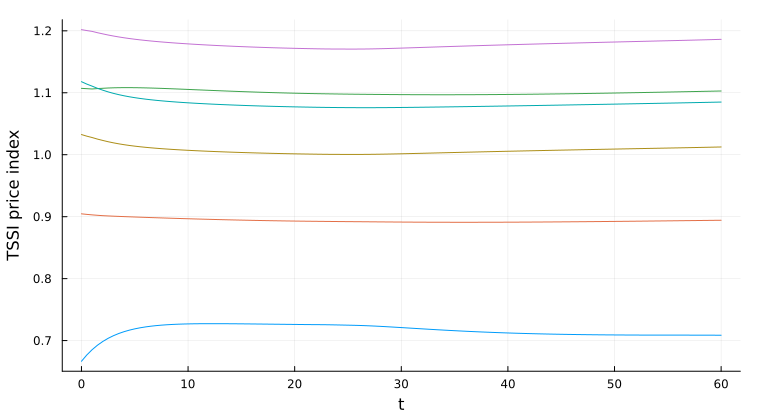

In [5]:
plot(v.t, v.p', xlabel = "t", ylabel = "TSSI price index", legend = false)

## 3. Do TSSI prices converge to simultaneist prices?

Freeze the data at one state. Then TSSI prices converge to the simultaneist prices `p★` if and only if the spectral radius of the exact Jacobian `∂p(t)/∂p(t − τ)` at `p★` is below one. Since the lag is single and fixed, stability does not depend on `τ`; `τ` only sets the time scale of convergence.

In [6]:
est = estabilidade_tssi(dados_tssi(sol.u[end], p))
(r★ = est.r★, raio_espectral = est.raio_espectral, taxa_convergência = est.taxa_convergência,
 estável = est.estável)

(r★ = 0.8688323787053485, raio_espectral = 0.23799777467770392, taxa_convergência = -1.4354939554480557, estável = true)

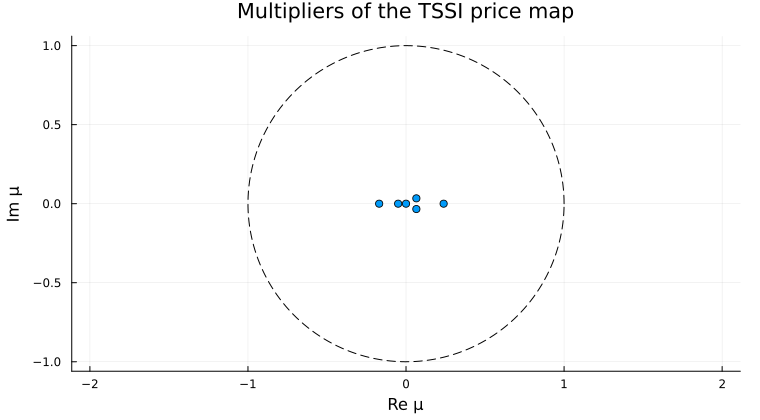

In [7]:
scatter(real.(est.multiplicadores), imag.(est.multiplicadores), legend = false,
        aspect_ratio = 1, xlabel = "Re μ", ylabel = "Im μ", title = "Multipliers of the TSSI price map")
θ = range(0, 2π, length = 200)
plot!(cos.(θ), sin.(θ), color = :black, ls = :dash)

## 4. Bifurcation in the scale of surplus value

`bifurcacao_tssi` scales total surplus value and continues the fixed point of the TSSI price map with BifurcationKit, marking any point where a multiplier leaves the unit circle. For this economy there is none in the range: the spectral radius stays well below one, so TSSI prices converge to simultaneist prices for every scale tried.

In [8]:
bt = bifurcacao_tssi(sol.u[end], p; τ = 1.0, escala = (0.05, 10.0))
[(pt.tipo, round(pt.θ, digits = 3)) for pt in bt.pontos]

Tuple{Any, Any}[]

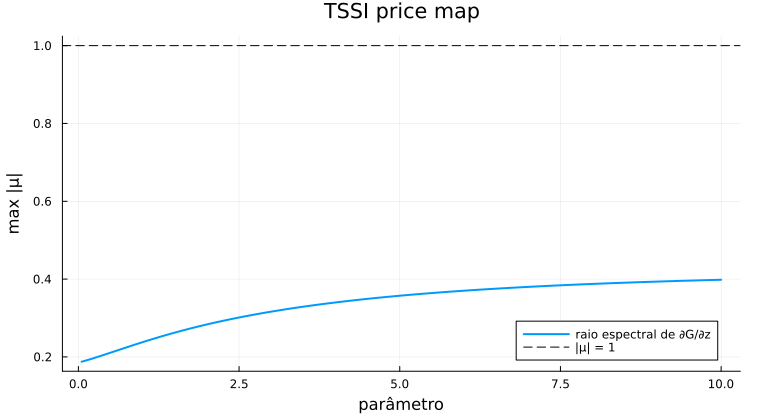

In [9]:
plotar_bifurcacao(bt; titulo = "TSSI price map")